In [ ]:
pip install -q ultralytics roboflow

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 34.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 373.9/373.9 kB 34.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 120.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.9/96.9 kB 11.4 MB/s eta 0:00:00


In [ ]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key=ROBOFLOW_API_KEY)
import os
ROBOFLOW_API_KEY = os.getenv("ROBOFLOW_API_KEY")
project = rf.workspace("site-construction-safety").project("site-construction-safety")
version = project.version(1)
dataset = version.download("yolov11")


loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Site-Construction-Safety-1 in yolov11:: 100%|██████████| 20876/20876 [00:04<00:00, 5163.21it/s]


In [ ]:

from pathlib import Path
import yaml

dataset_dir = Path(dataset.location)
yaml_path = dataset_dir / "data.yaml"

print("Dataset directory:", dataset_dir)
print("YAML exists:", yaml_path.exists())

with open(yaml_path, "r") as f:
    config = yaml.safe_load(f)

print("\nClasses:", config["names"])
print("Number of classes:", config["nc"])

print("\nFolders:")
for item in dataset_dir.iterdir():
    print(item.name)


Dataset directory: /content/Site-Construction-Safety-1
YAML exists: True

Classes: ['Gloves', 'Helmet', 'Non-Helmet', 'Person', 'Shoes', 'Vest', 'bare-arms']
Number of classes: 7

Folders:
test
README.roboflow.txt
train
README.dataset.txt
valid
data.yaml


train: 9861 images, 9861 label files
valid: 340 images, 340 label files
test: 231 images, 231 label files


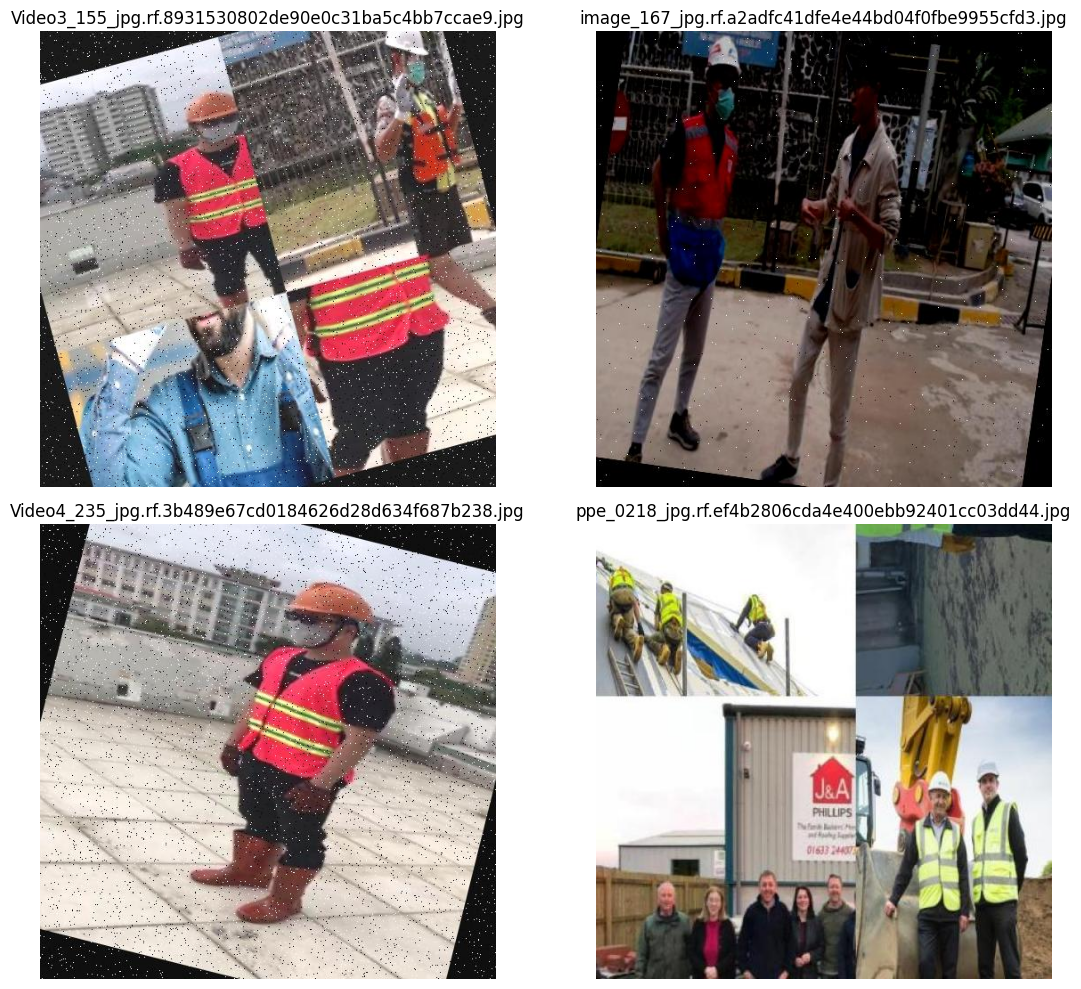

In [ ]:

from pathlib import Path
import random
import matplotlib.pyplot as plt
import cv2

dataset_dir = Path("/content/Site-Construction-Safety-1")

for split in ["train", "valid", "test"]:
    images_dir = dataset_dir / split / "images"
    labels_dir = dataset_dir / split / "labels"

    images = list(images_dir.glob("*")) if images_dir.exists() else []
    labels = list(labels_dir.glob("*.txt")) if labels_dir.exists() else []

    print(f"{split}: {len(images)} images, {len(labels)} label files")

# Display 4 random training images
train_images = list((dataset_dir / "train" / "images").glob("*"))
sample_images = random.sample(train_images, min(4, len(train_images)))

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, image_path in zip(axes.flat, sample_images):
    image = cv2.imread(str(image_path))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    ax.imshow(image)
    ax.set_title(image_path.name)
    ax.axis("off")

plt.tight_layout()
plt.show()


In [ ]:

from ultralytics import YOLO
import torch

# Load pretrained YOLO11 nano model
model = YOLO("yolo11n.pt")

# Train on our custom construction safety dataset
results = model.train(
    data="/content/Site-Construction-Safety-1/data.yaml",
    epochs=50,
    imgsz=640,
    batch=16,
    device='cpu',
    workers=2,
    project="/content/construction_safety",
    name="yolo11n_safety",
    plots=True,
    patience=10
)


Ultralytics 8.4.175 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Site-Construction-Safety-1/data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo11n_safety, nbs=64, nms=None, opset=

KeyboardInterrupt: 

# UPLOAD MODEL

In [ ]:

from google.colab import files
from ultralytics import YOLO
import os

# Upload best.pt if it isn't already in this runtime
if not os.path.exists("best.pt"):
    uploaded_model = files.upload()
    model_path = next(iter(uploaded_model.keys()))
else:
    model_path = "best.pt"

model = YOLO(model_path)

print("Model loaded successfully!")
print("Detected classes:", model.names)


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


Saving best.pt to best.pt
Model loaded successfully!
Detected classes: {0: 'Gloves', 1: 'Helmet', 2: 'Non-Helmet', 3: 'Person', 4: 'Shoes', 5: 'Vest', 6: 'bare-arms'}


#UPLOAD INPUT VIDEO

In [ ]:

from google.colab import files

uploaded = files.upload()


Saving workersss.mp4 to workersss.mp4


#CHECK PATH OF UPLOADED INPUT VIDEO

In [ ]:

video_path = next(iter(uploaded.keys()))
print("Uploaded video:", video_path)


Uploaded video: workersss.mp4


In [ ]:
"""
Construction-site PPE monitor (v4)
Dataset: Roboflow "site-construction-safety"
Classes: Helmet, Non-Helmet, Vest, Gloves, Shoes, bare-arms, Person

What changed vs v3
- Vest and Gloves are now checked (v3 never looked at them).
- "Missing" is inferred from ABSENCE: the dataset has no "no-vest / no-gloves /
  no-shoes" classes, so v3 could never flag those. Now, if a worker is clearly
  visible for a while and the item is not found, the score slowly drifts to "missing".
- Absence is only counted when the body part can actually be seen
  (worker big enough, feet/head not cut off by the frame, not hidden behind another worker).
- Status uses hysteresis -> no flickering between SAFE / VIOLATION.
- PPE boxes are matched to workers by overlap + body region (gloves get wide side padding
  because hands stick out of the person box).
- Worker count: on-screen now + total unique workers seen in the video.
- Per-item chips on each worker (H V G S), a per-worker CSV report at the end.
"""
from ultralytics import YOLO
from pathlib import Path
import csv
import subprocess
import cv2
import torch

# ============================ CONFIG ============================
VIDEO_PATH  = "/content/workersss.mp4"
MODEL_PATH  = "/content/best.pt"
OUTPUT_PATH = "/content/construction_safety_v4.mp4"
REPORT_PATH = "/content/worker_report.csv"

PERSON_SOURCE = "custom"  # "custom" = Person class from best.pt, "coco" = pretrained yolo11s.pt
IMGSZ       = 960         # bigger helps small items (gloves, shoes). Compare 640 / 960 / 1280.
PERSON_CONF = 0.40        # a track is only started/kept on detections at least this confident
PPE_CONF    = 0.30        # PPE detection confidence
PPE_EVERY   = 1           # run the PPE model every N frames (2 = faster, slightly slower reaction)
MIN_HITS    = 5           # frames a track must exist before it is drawn
EDGE        = 4           # px: a box touching the frame edge is "cut off"

# Evidence smoothing (per worker, per item). Score 1 = wearing it, 0 = not wearing it.
ALPHA_SEEN   = 0.30   # weight of an actual detection (item found, or explicit Non-Helmet / bare-arms)
ALPHA_MISS   = 0.04   # weight of "should be visible but nothing was detected"
OK_T, BAD_T  = 0.65, 0.30   # hysteresis thresholds
MIN_EVIDENCE = 8      # updates needed before any verdict for an item

# Class names are matched in lowercase.
#   y      = (top, bottom) vertical band of the worker box where the item may sit (can go <0 or >1)
#   pad_x  = extra horizontal room as a fraction of worker width (hands stick out!)
#   min_h  = worker box height (px) needed before we trust "not detected" for this item
#   absent = score target when nothing is detected (0 = treat as missing, 1 = treat as fine,
#            None = absence tells us nothing)
ITEMS = {
    "helmet": {"ok": {"helmet"}, "bad": {"non-helmet"}, "y": (-0.20, 0.30), "pad_x": 0.10,
               "min_h": 50,  "absent": 0.0, "tag": "H", "missing": "NO HELMET"},
    "vest":   {"ok": {"vest"},   "bad": set(),           "y": (0.10, 0.75), "pad_x": 0.05,
               "min_h": 60,  "absent": 0.0, "tag": "V", "missing": "NO VEST"},
    "gloves": {"ok": {"gloves"}, "bad": set(),           "y": (0.15, 0.95), "pad_x": 0.35,
               "min_h": 110, "absent": 0.0, "tag": "G", "missing": "NO GLOVES"},
    "shoes":  {"ok": {"shoes"},  "bad": set(),           "y": (0.75, 1.10), "pad_x": 0.15,
               "min_h": 110, "absent": 0.0, "tag": "S", "missing": "NO SHOES"},
    "arms":   {"ok": set(),      "bad": {"bare-arms"},   "y": (0.10, 0.80), "pad_x": 0.30,
               "min_h": 80,  "absent": 1.0, "tag": "A", "missing": "BARE ARMS"},
}
REQUIRED = ["helmet", "vest", "gloves", "shoes"]   # all must be OK for SAFE
ALERT    = REQUIRED + ["arms"]                      # any of these "bad" -> VIOLATION (drop "arms" if not needed)

GREEN, RED, AMBER, GREY = (70, 200, 70), (50, 50, 235), (0, 190, 255), (130, 130, 130)
# ================================================================

device = 0 if torch.cuda.is_available() else "cpu"
use_half = device == 0
print("Device:", "GPU" if use_half else "CPU (enable GPU: Runtime > Change runtime type)")

ppe_model = YOLO(MODEL_PATH)
names = {i: n.lower() for i, n in ppe_model.names.items()}
print("Model classes:", names)

LOOKUP = {}   # class name -> (item, target)
for item, cfg in ITEMS.items():
    for n in cfg["ok"]:
        LOOKUP[n] = (item, 1.0)
    for n in cfg["bad"]:
        LOOKUP[n] = (item, 0.0)
not_in_model = set(LOOKUP) - set(names.values())
if not_in_model:
    print("WARNING: these names are not in your model, fix ITEMS:", sorted(not_in_model))
PPE_CLASSES = [i for i, n in names.items() if n in LOOKUP]

# Person tracker: a separate YOLO instance, because calling predict() on the same object
# would reset its tracker state.
person_ids = [i for i, n in names.items() if n == "person"]
if PERSON_SOURCE == "custom" and person_ids:
    track_model, PERSON_CLASSES = YOLO(MODEL_PATH), person_ids
    print("Tracking workers with the 'Person' class of your model")
else:
    track_model, PERSON_CLASSES = YOLO("yolo11s.pt"), [0]
    print("Tracking workers with pretrained yolo11s (COCO person)")

# ByteTrack tuned for a site: low-confidence boxes still keep an existing track alive,
# lost tracks are remembered ~3 s so a worker passing behind something keeps the same ID.
TRACKER_CFG = str(Path(OUTPUT_PATH).with_name("bytetrack_site.yaml"))
Path(TRACKER_CFG).write_text(
    "tracker_type: bytetrack\n"
    f"track_high_thresh: {PERSON_CONF}\n"
    "track_low_thresh: 0.1\n"
    f"new_track_thresh: {PERSON_CONF + 0.05:.2f}\n"
    "track_buffer: 90\n"
    "match_thresh: 0.8\n"
    "fuse_score: True\n"
)

cap = cv2.VideoCapture(VIDEO_PATH)
if not cap.isOpened():
    raise FileNotFoundError(VIDEO_PATH)
fps = cap.get(cv2.CAP_PROP_FPS) or 25
W = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
H = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

writer = cv2.VideoWriter(OUTPUT_PATH, cv2.VideoWriter_fourcc(*"mp4v"), fps, (W, H))
if not writer.isOpened():
    raise RuntimeError("Could not create output video.")

state = {}          # wid -> item -> {"score", "n", "status"}
hits = {}           # wid -> frames tracked
first_seen, last_seen = {}, {}
ever_violated = {}  # wid -> set of violation texts
MIN_TRACK_FOR_TOTAL = max(MIN_HITS, int(fps))   # ignore tracks shorter than ~1 s in the total count


# ---------------------------------------------------------------- helpers
def iou(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / union if union > 0 else 0.0


def occluded_ids(workers):
    """Workers heavily overlapping another worker: don't trust 'not detected' for them."""
    ids, out = list(workers), set()
    for i in range(len(ids)):
        for j in range(i + 1, len(ids)):
            if iou(workers[ids[i]], workers[ids[j]]) > 0.30:
                out.update((ids[i], ids[j]))
    return out


def visible(box, item):
    x1, y1, x2, y2 = box
    if y2 - y1 < ITEMS[item]["min_h"]:
        return False
    if item == "helmet" and y1 <= EDGE:
        return False                      # head cut off by the frame
    if item == "shoes" and y2 >= H - EDGE:
        return False                      # feet cut off by the frame
    if item in ("gloves", "arms") and (x1 <= EDGE or x2 >= W - EDGE):
        return False
    return True


def match_worker(pbox, item, workers):
    """Worker that this PPE box belongs to, or None."""
    px1, py1, px2, py2 = pbox
    cx, cy = (px1 + px2) / 2, (py1 + py2) / 2
    parea = max(1.0, (px2 - px1) * (py2 - py1))
    top, bottom = ITEMS[item]["y"]
    pad = ITEMS[item]["pad_x"]
    best, best_score = None, -1e9
    for wid, (x1, y1, x2, y2) in workers.items():
        w, h = x2 - x1, y2 - y1
        rx1, rx2 = x1 - pad * w, x2 + pad * w
        ry1, ry2 = y1 + top * h, y1 + bottom * h
        if not (rx1 <= cx <= rx2 and ry1 <= cy <= ry2):
            continue
        if (px2 - px1) > 1.5 * w:          # PPE box far wider than the worker -> not theirs
            continue
        ix = max(0, min(px2, rx2) - max(px1, rx1))
        iy = max(0, min(py2, ry2) - max(py1, ry1))
        score = ix * iy / parea - 0.3 * abs(cx - (x1 + x2) / 2) / max(w, 1)
        if score > best_score:
            best, best_score = wid, score
    return best


def update_evidence(workers, det):
    found = {}   # (wid, item) -> (target, conf), strongest evidence this frame
    if det is not None and det.boxes is not None:
        for xyxy, c, cf in zip(det.boxes.xyxy.cpu().tolist(),
                               det.boxes.cls.int().cpu().tolist(),
                               det.boxes.conf.cpu().tolist()):
            item, target = LOOKUP[names[c]]
            wid = match_worker(xyxy, item, workers)
            if wid is None:
                continue
            if (wid, item) not in found or cf > found[(wid, item)][1]:
                found[(wid, item)] = (target, cf)

    hidden = occluded_ids(workers)
    for wid, box in workers.items():
        for item, cfg in ITEMS.items():
            rec = state.setdefault(wid, {}).setdefault(item, {"score": 0.5, "n": 0, "status": None})
            if (wid, item) in found:
                target, a = found[(wid, item)][0], ALPHA_SEEN
            elif cfg["absent"] is not None and wid not in hidden and visible(box, item):
                target, a = cfg["absent"], ALPHA_MISS
            else:
                continue                    # can't see it -> keep previous belief
            rec["score"] += a * (target - rec["score"])
            rec["n"] += 1
            if rec["n"] >= MIN_EVIDENCE:    # hysteresis: only flip when a threshold is crossed
                if rec["score"] >= OK_T:
                    rec["status"] = "ok"
                elif rec["score"] <= BAD_T:
                    rec["status"] = "bad"


def worker_summary(wid):
    recs = state.get(wid, {})
    st = {item: recs.get(item, {}).get("status") for item in ITEMS}
    missing = [ITEMS[i]["missing"] for i in ALERT if st[i] == "bad"]
    if missing:
        ever_violated.setdefault(wid, set()).update(missing)
        return RED, "VIOLATION", st, missing
    if all(st[i] == "ok" for i in REQUIRED):
        return GREEN, "SAFE", st, missing
    return AMBER, "CHECKING", st, missing


def draw_worker(img, box, color, wid, st):
    x1, y1, x2, y2 = map(int, box)
    t, L = 2, max(12, int(min(x2 - x1, y2 - y1) * 0.18))
    for (px, py, dx, dy) in [(x1, y1, 1, 1), (x2, y1, -1, 1), (x1, y2, 1, -1), (x2, y2, -1, -1)]:
        cv2.line(img, (px, py), (px + dx * L, py), color, t, cv2.LINE_AA)
        cv2.line(img, (px, py), (px, py + dy * L), color, t, cv2.LINE_AA)

    # label: "#id" + one chip per item (green = wearing, red = missing, grey = not decided yet)
    chips = [i for i in REQUIRED] + [i for i in ALERT if i not in REQUIRED and st[i] == "bad"]
    label = f"#{wid}"
    (tw, th), _ = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, 0.5, 1)
    cs = 16
    bw = tw + 14 + len(chips) * (cs + 3)
    ly = y1 - 8 if y1 - cs - 14 > 0 else y2 + cs + 10
    cv2.rectangle(img, (x1, ly - cs - 4), (x1 + bw, ly + 4), color, -1)
    cv2.putText(img, label, (x1 + 5, ly - 2), cv2.FONT_HERSHEY_SIMPLEX, 0.5,
                (255, 255, 255), 1, cv2.LINE_AA)
    cx = x1 + tw + 10
    for item in chips:
        s = st[item]
        cc = GREEN if s == "ok" else RED if s == "bad" else GREY
        cv2.rectangle(img, (cx, ly - cs), (cx + cs, ly), cc, -1)
        cv2.rectangle(img, (cx, ly - cs), (cx + cs, ly), (255, 255, 255), 1)
        cv2.putText(img, ITEMS[item]["tag"], (cx + 4, ly - 4), cv2.FONT_HERSHEY_SIMPLEX, 0.42,
                    (255, 255, 255), 1, cv2.LINE_AA)
        cx += cs + 3


def draw_hud(img, n_now, n_total, n_safe, n_viol, n_check, miss_counts, frame_idx):
    lines = [("SITE SAFETY MONITOR", (255, 255, 255)),
             (f"Workers on screen : {n_now}", (255, 255, 255)),
             (f"Total workers seen: {n_total}", (255, 255, 255)),
             (f"Safe      : {n_safe}", GREEN),
             (f"Violations: {n_viol}", RED if n_viol else (200, 200, 200)),
             (f"Checking  : {n_check}", AMBER)]
    for item in ALERT:
        if miss_counts[item]:
            lines.append((f"  {ITEMS[item]['missing']}: {miss_counts[item]}", RED))
    x, y, w, h = 10, 10, 250, 16 + 20 * len(lines)
    over = img.copy()
    cv2.rectangle(over, (x, y), (x + w, y + h), (20, 20, 20), -1)
    cv2.addWeighted(over, 0.65, img, 0.35, 0, dst=img)
    for i, (s, c) in enumerate(lines):
        cv2.putText(img, s, (x + 10, y + 22 + i * 20), cv2.FONT_HERSHEY_SIMPLEX, 0.5, c, 1, cv2.LINE_AA)
    legend = "  ".join(f"{ITEMS[i]['tag']}={i}" for i in REQUIRED)
    cv2.putText(img, legend, (10, H - 12), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (220, 220, 220), 1, cv2.LINE_AA)
    cv2.putText(img, f"Frame {frame_idx}/{total}", (W - 160, H - 12),
                cv2.FONT_HERSHEY_SIMPLEX, 0.45, (220, 220, 220), 1, cv2.LINE_AA)


# ---------------------------------------------------------------- main loop
frame_idx = 0
try:
    while True:
        ok, frame = cap.read()
        if not ok:
            break
        frame_idx += 1

        # 1. track workers
        tr = track_model.track(frame, persist=True, tracker=TRACKER_CFG, classes=PERSON_CLASSES,
                               conf=0.1, imgsz=IMGSZ, device=device, half=use_half, verbose=False)[0]
        workers = {}
        if tr.boxes is not None and tr.boxes.id is not None:
            for box, wid in zip(tr.boxes.xyxy.cpu().tolist(), tr.boxes.id.int().cpu().tolist()):
                hits[wid] = hits.get(wid, 0) + 1
                first_seen.setdefault(wid, frame_idx)
                last_seen[wid] = frame_idx
                if hits[wid] >= MIN_HITS:
                    workers[wid] = box

        # 2. PPE detection + evidence update
        if workers and frame_idx % PPE_EVERY == 0:
            det = ppe_model.predict(frame, conf=PPE_CONF, classes=PPE_CLASSES, imgsz=IMGSZ,
                                    device=device, half=use_half, verbose=False)[0]
            update_evidence(workers, det)

        # 3. draw
        n_safe = n_viol = n_check = 0
        miss_counts = {i: 0 for i in ALERT}
        for wid, box in workers.items():
            color, verdict, st, _ = worker_summary(wid)
            n_safe += verdict == "SAFE"
            n_viol += verdict == "VIOLATION"
            n_check += verdict == "CHECKING"
            for i in ALERT:
                miss_counts[i] += st[i] == "bad"
            draw_worker(frame, box, color, wid, st)

        n_total = sum(1 for v in hits.values() if v >= MIN_TRACK_FOR_TOTAL)
        draw_hud(frame, len(workers), n_total, n_safe, n_viol, n_check, miss_counts, frame_idx)
        writer.write(frame)

        if frame_idx % 50 == 0:
            print(f"Processed {frame_idx}/{total} frames | on screen {len(workers)} | total {n_total}")
finally:
    cap.release()
    writer.release()

# ---------------------------------------------------------------- report
counted = [w for w, v in hits.items() if v >= MIN_TRACK_FOR_TOTAL]
with open(REPORT_PATH, "w", newline="") as f:
    wr = csv.writer(f)
    wr.writerow(["worker_id", "first_frame", "last_frame", "seconds_on_screen"]
                + [f"{i}_final" for i in ITEMS] + ["ever_violated"])
    for wid in sorted(counted):
        recs = state.get(wid, {})
        wr.writerow([wid, first_seen[wid], last_seen[wid], round(hits[wid] / fps, 1)]
                    + [recs.get(i, {}).get("status") or "unknown" for i in ITEMS]
                    + ["; ".join(sorted(ever_violated.get(wid, []))) or "-"])

print("\nSaved:", OUTPUT_PATH, "| exists:", Path(OUTPUT_PATH).exists())
print("Total workers seen:", len(counted))
print("Workers ever flagged:", {k: sorted(v) for k, v in ever_violated.items()} or "none")
print("Report:", REPORT_PATH)

# Colab can't play 'mp4v' in the browser -> convert to H.264
try:
    web = OUTPUT_PATH.replace(".mp4", "_web.mp4")
    subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", OUTPUT_PATH,
                    "-vcodec", "libx264", "-pix_fmt", "yuv420p", web], check=True)
    print("Browser-friendly copy:", web)
except Exception as e:
    print("ffmpeg conversion skipped:", e)

Device: GPU
Model classes: {0: 'gloves', 1: 'helmet', 2: 'non-helmet', 3: 'person', 4: 'shoes', 5: 'vest', 6: 'bare-arms'}
Tracking workers with the 'Person' class of your model
requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
Using Python 3.13.15 environment at: /usr
Resolved 2 packages in 343ms
Prepared 1 package in 55ms
Installed 1 package in 1ms
 + lap==0.5.13

requirements: AutoUpdate success ✅ 0.9s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️

#DOWNLOAD OUTPUT VIDEO

In [ ]:
from google.colab import files
files.download("/content/construction_safety_v4_web.mp4")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

#use ssh

In [18]:
!pip install -q ultralytics
!wget -q https://github.com/ahmadmughees/SH17dataset/releases/download/v1/yolo8m.pt -O /content/sh17_yolo8m.pt

from ultralytics import YOLO
m = YOLO("/content/sh17_yolo8m.pt")
print(m.names)

{0: 'person', 1: 'ear', 2: 'ear-mufs', 3: 'face', 4: 'face-guard', 5: 'face-mask', 6: 'foot', 7: 'tool', 8: 'glasses', 9: 'gloves', 10: 'helmet', 11: 'hands', 12: 'head', 13: 'medical-suit', 14: 'shoes', 15: 'safety-suit', 16: 'safety-vest'}


In [6]:

from google.colab import files

uploaded = files.upload()


Saving test_video.mp4 to test_video (1).mp4


In [19]:
m.predict("/content/test_video.mp4", save=True, conf=0.3, imgsz=640)


WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

video 1/1 (frame 1/411) /content/test_video.mp4: 384x640 2 persons, 1 gloves, 1 helmet, 2 handss, 2 heads, 3 shoess, 2 safety-vests, 48.7ms
video 1/1 (frame 2/411) /content/test_video.mp4: 384x640 2 persons, 1 helmet, 2 handss, 2 heads, 3 shoess, 2 safety-vests, 47.7ms
video 1/1 (frame 3/411) /content/test_video.mp4: 384x640 2 persons, 1 gloves, 1 helmet, 2 handss, 2 heads, 3 shoess, 2 safety-vests, 34.0ms
video 1/1 (frame 4/411) /content/test_video.mp4: 

[ultralytics.engine.results.Results object with attributes:
 
 boxes: ultralytics.engine.results.Boxes object
 depth: None
 keypoints: None
 masks: None
 names: {0: 'person', 1: 'ear', 2: 'ear-mufs', 3: 'face', 4: 'face-guard', 5: 'face-mask', 6: 'foot', 7: 'tool', 8: 'glasses', 9: 'gloves', 10: 'helmet', 11: 'hands', 12: 'head', 13: 'medical-suit', 14: 'shoes', 15: 'safety-suit', 16: 'safety-vest'}
 obb: None
 orig_img: array([[[  0,   0,   0],
         [  0,   0,   0],
         [  0,   0,   1],
         ...,
         [ 30,  31,  24],
         [ 46,  47,  40],
         [ 53,  54,  47]],
 
        [[  0,   0,   0],
         [  0,   0,   0],
         [  0,   0,   1],
         ...,
         [ 32,  33,  26],
         [ 44,  45,  38],
         [ 48,  49,  42]],
 
        [[  0,   0,   0],
         [  0,   0,   0],
         [  0,   0,   1],
         ...,
         [ 25,  26,  19],
         [ 38,  39,  32],
         [ 39,  40,  33]],
 
        ...,
 
        [[  0,   0,   0],
         [  0,  

In [1]:
!python /content/construction_safety_v9_sh17.py

Device: GPU
Model classes: {0: 'person', 1: 'ear', 2: 'ear-mufs', 3: 'face', 4: 'face-guard', 5: 'face-mask', 6: 'foot', 7: 'tool', 8: 'glasses', 9: 'gloves', 10: 'helmet', 11: 'hands', 12: 'head', 13: 'medical-suit', 14: 'shoes', 15: 'safety-suit', 16: 'safety-vest'}
Tracking workers with the model's 'Person' class
Fonts: Rajdhani
PASS 1/2: analysing the video ...
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' inst

In [2]:
from google.colab import files
files.download("/content/safety_v9_web.mp4")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>